# 02 · Exact Method: Cardinality-Constrained Portfolio Optimisation as a MILP

**Question:** which ≤ 5 of 457 S&P 500 stocks should we buy with $10,000, and how much of each, to reach a **20% expected annual return with the minimum risk**?

**Method:** a **Mixed-Integer Linear Program** (cardinality-constrained Mean-Absolute-Deviation model), solved to proven optimality, or to a certified gap, by **LP-based Branch & Bound** (HiGHS solver through PuLP; CBC as a cross-check).

**Contents**
1. Setup and problem parameters
2. Loading the problem instance (cleaned data from notebook 01)
3. Mathematical formulation
4. Implementation: building the MILP in PuLP
5. Implementation: solving it and reading the solver's proof (bound and gap)
6. A method-independent evaluator (shared with the heuristic)
7. Worked example: LP relaxation vs Branch & Bound on 10 stocks
8. Verification: is the "exact" answer really optimal?
9. Experiments: full problem, scalability, solver comparison, efficient frontier, sensitivity to K
10. Out-of-sample validation (2017–2018)
11. Export for the comparison with the heuristic
12. Discussion and future work

> **Running time.** The full experiments take about 2.5 hours (some solves run for 30 minutes). Their results are saved in `results/exact/`. With `RUN_EXPERIMENTS = False` (default), the notebook **loads** those saved results and runs in about a minute. Set it to `True` to recompute everything from scratch.

## 1. Setup and problem parameters

In [1]:
import itertools
import json
import math
import time
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import pulp
from scipy.optimize import linprog
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

pd.set_option("display.float_format", "{:.5f}".format)
print("PuLP", pulp.__version__, "| solvers available:", pulp.listSolvers(onlyAvailable=True))

PuLP 3.3.2 | solvers available: ['GLPK_CMD', 'PULP_CBC_CMD', 'HiGHS']


**Investor parameters (Option C).** Every number the model uses is defined once here.

| Symbol | Value | Meaning |
|---|---|---|
| $B$ | \$10,000 | budget |
| $K$ | 5 | maximum number of stocks held (the investor can only follow 5 companies) |
| $l$ | 5% | minimum position size if a stock is bought (no meaningless 0.1% holdings) |
| $u$ | 40% | maximum position size (forces diversification: at least 3 stocks) |
| $\rho$ | 20% / 52 | required expected **weekly** return (20% per year) |
| cash | ≤ 1% | whole-share plans may leave at most $100 unspent |

In [2]:
BUDGET = 10_000.0
MAX_ASSETS = 5                 # K
MIN_WEIGHT = 0.05              # l
MAX_WEIGHT = 0.40              # u
TARGET_ANNUAL_RETURN = 0.20    # rho * 52
MAX_CASH = 0.01                # whole-share variant only
PERIODS_PER_YEAR = 52          # weekly data

RUN_EXPERIMENTS = False        # True = recompute all experiments (~2.5 h); False = load saved results
TIME_LIMIT = 300               # seconds per solve in the experiments
MAIN_TIME_LIMIT = 1800         # seconds for the headline full-size solve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results" / "exact"
FIGURES_DIR = ROOT / "results" / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Same figure style as notebook 01 (colour-blind-safe palette, light grid)
BLUE, ORANGE, GREEN, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "axes.titlelocation": "left", "axes.titleweight": "semibold", "axes.titlesize": 12,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.prop_cycle": mpl.cycler(color=[BLUE, ORANGE, GREEN]),
    "legend.frameon": False, "lines.linewidth": 2,
})

def save(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{name}.png")

## 2. Loading the problem instance
Notebook 01 cleaned the Kaggle data and saved it to `data/processed/`. Here we read:
* `weekly_returns_train.csv`: the matrix $r_{ti}$ (203 weeks × 457 stocks) that defines the model;
* `daily_close_clean.csv`: daily prices, used for the decision-date share prices $p_i$ and for the out-of-sample test.

In [4]:
train = pd.read_csv(PROCESSED_DIR / "weekly_returns_train.csv", index_col=0, parse_dates=True)
daily_prices = pd.read_csv(PROCESSED_DIR / "daily_close_clean.csv", index_col=0, parse_dates=True)
decision_prices = daily_prices.loc[:"2016-12-31"].iloc[-1]     # close on 2016-12-30

print(f"returns: {train.shape[0]} weeks x {train.shape[1]} stocks, "
      f"{train.index.min().date()} → {train.index.max().date()}")
print(f"decision date: {daily_prices.loc[:'2016-12-31'].index[-1].date()}")

returns: 203 weeks x 457 stocks, 2013-02-15 → 2016-12-30
decision date: 2016-12-30


**The `Instance` class** bundles everything that defines one problem: the return data, the prices, and the parameters $K, l, u, \rho$. Bundling them lets us create smaller or modified problems easily (random subsets for the scalability study, other values of $K$, other targets) with `replace(...)`.

It also computes the derived model parameters:
* `mu`: $\mu_i = \frac{1}{T}\sum_t r_{ti}$, the expected weekly return of each stock;
* `deviations`: $a_{ti} = r_{ti} - \mu_i$, how far each stock is from its mean in each week, which is the building block of MAD;
* `max_achievable_return`: the highest return any feasible portfolio can reach. Fill the best stocks up to $u$ each; greedy is optimal for this small LP. A target above this value is infeasible.

In [5]:
@dataclass
class Instance:
    returns: pd.DataFrame                  # T x N weekly returns r_ti
    prices: pd.Series                      # price p_i on the decision date
    K: int = MAX_ASSETS
    w_min: float = MIN_WEIGHT
    w_max: float = MAX_WEIGHT
    target: float = TARGET_ANNUAL_RETURN / PERIODS_PER_YEAR   # rho (weekly)
    budget: float = BUDGET
    max_cash: float = MAX_CASH

    def __post_init__(self):
        self.prices = self.prices.loc[self.returns.columns]    # keep prices aligned with stocks

    @property
    def tickers(self): return list(self.returns.columns)
    @property
    def N(self): return self.returns.shape[1]
    @property
    def T(self): return self.returns.shape[0]
    @property
    def mu(self): return self.returns.values.mean(axis=0)
    @property
    def deviations(self): return self.returns.values - self.mu

    def max_achievable_return(self):
        remaining, total = 1.0, 0.0
        for m in np.sort(self.mu)[::-1][: self.K]:
            w = min(self.w_max, remaining)
            total, remaining = total + w * m, remaining - w
            if remaining <= 1e-12:
                return total
        return -np.inf

    def subset(self, tickers, **changes):
        return replace(self, returns=self.returns[tickers], **changes)


def random_subinstance(inst, n, seed):
    """n randomly chosen stocks (reproducible via seed). A random subset may not contain
    stocks good enough for the 20% target, so the target is capped at 90% of what the
    subset can achieve - this keeps every sampled instance feasible."""
    rng = np.random.default_rng(seed)
    tickers = sorted(rng.choice(inst.tickers, size=n, replace=False))
    target = min(inst.target, 0.9 * inst.subset(tickers).max_achievable_return())
    return inst.subset(tickers, target=target)


inst = Instance(returns=train, prices=decision_prices)
print(f"N = {inst.N} stocks, T = {inst.T} weeks, K = {inst.K}, weights in [{inst.w_min:.0%}, {inst.w_max:.0%}], "
      f"target = {inst.target * 52:.0%}/yr (max achievable {inst.max_achievable_return() * 52:.0%}/yr)")

N = 457 stocks, T = 203 weeks, K = 5, weights in [5%, 40%], target = 20%/yr (max achievable 57%/yr)


## 3. Mathematical formulation

**Sets and indices**
* $i \in \{1,\dots,N\}$: candidate stocks ($N = 457$)
* $t \in \{1,\dots,T\}$: weekly scenarios in the estimation window ($T = 203$)

**Parameters (from the data)**
* $r_{ti}$: return of stock $i$ in week $t$
* $\mu_i = \frac{1}{T}\sum_t r_{ti}$: expected weekly return of stock $i$
* $a_{ti} = r_{ti} - \mu_i$: deviation of stock $i$ from its mean in week $t$
* $\rho$: required expected return ($20\%/52$ per week); $K = 5$; $l = 0.05$; $u = 0.40$

**Decision variables**
* $w_i \in [0, u]$: fraction of the budget invested in stock $i$ (continuous)
* $z_i \in \{0, 1\}$: 1 if stock $i$ is bought (binary)
* $d_t \ge 0$: absolute deviation of the portfolio return in week $t$ (auxiliary)

**Model (CC-MAD)**
$$
\begin{aligned}
\min_{w,z,d}\quad & \frac{1}{T}\sum_{t=1}^{T} d_t && \text{(mean absolute deviation = risk)}\\
\text{s.t.}\quad & d_t \ \ge\ \ \ \sum_{i} a_{ti} w_i && \forall t \quad (1)\\
& d_t \ \ge\ -\sum_{i} a_{ti} w_i && \forall t \quad (2)\\
& \sum_{i} w_i = 1 && (3)\ \text{fully invested}\\
& \sum_{i} \mu_i w_i \ \ge\ \rho && (4)\ \text{return target}\\
& \sum_{i} z_i \ \le\ K && (5)\ \text{at most 5 stocks}\\
& l\, z_i \ \le\ w_i \ \le\ u\, z_i && \forall i \quad (6)\ \text{linking}\\
& z_i \in \{0,1\},\ w_i \ge 0,\ d_t \ge 0
\end{aligned}
$$

**How each part works**
* **Objective.** The risk is the average size of the portfolio's weekly deviation from its own mean: $\frac1T\sum_t |\sum_i a_{ti}w_i|$.
* **(1)–(2) linearise the absolute value.** $d_t$ must be at least $+x$ and at least $-x$, so $d_t \ge |x|$. Because we *minimise* $d_t$, at the optimum $d_t = |x|$ exactly. This trick keeps the model linear, so PuLP can solve it.
* **(3)** all money is invested. **(4)** the expected return meets the target.
* **(5)** is the **cardinality constraint**. Only (5), together with the binaries, makes the problem combinatorial; without it the model is a plain LP.
* **(6) is a Big-M linking constraint** (here $M = u$). If $z_i = 0$ then $w_i = 0$: a stock cannot receive money unless it is "picked". If $z_i = 1$ then $l \le w_i \le u$.

**Whole-share variant (realistic purchase plan).** Let $p_i$ be the price on the decision date, $B$ the budget and $x_i \in \mathbb{Z}_{\ge 0}$ the number of shares bought. Add $B\,w_i = p_i\,x_i$, and replace (3) by $1 - c \le \sum_i w_i \le 1$, where $c$ = 1% is the cash left over from rounding to whole shares.

**Why MAD and not variance (Markowitz)?** Variance makes the objective *quadratic* (an MIQP), and PuLP handles **linear** models only. MAD (Konno & Yamazaki, 1991) keeps the risk–return trade-off with linear constraints, and it is more robust to the fat-tailed returns found in notebook 01.

**Problem class.** With constraint (5) the problem is **NP-hard** (Bienstock, 1996; Moral-Escudero et al., 2006). It contains subset selection: choosing ≤ 5 of 457 stocks gives about $1.6 \times 10^{11}$ subsets, and each needs its weights optimised.

## 4. Implementation: building the MILP in PuLP
`build_model` turns the formulation into a PuLP model **line by line**; the comments refer to the equation numbers above.

Two options are used later:
* `integer_shares=True` adds the whole-share variables $x_i$;
* `relax=True` makes $z_i$ (and $x_i$) continuous. This gives the **LP relaxation**, which is exactly what Branch & Bound solves at its first (root) node.

In [6]:
def build_model(inst, integer_shares=False, relax=False):
    N, T = inst.N, inst.T
    a, mu = inst.deviations, inst.mu
    binary = pulp.LpContinuous if relax else pulp.LpBinary
    integer = pulp.LpContinuous if relax else pulp.LpInteger

    m = pulp.LpProblem("CC_MAD_portfolio", pulp.LpMinimize)

    # decision variables
    w = [m.add_variable(f"w_{i}", lowBound=0, upBound=inst.w_max) for i in range(N)]       # weights
    z = [m.add_variable(f"z_{i}", lowBound=0, upBound=1, cat=binary) for i in range(N)]    # pick stock i?
    d = [m.add_variable(f"d_{t}", lowBound=0) for t in range(T)]                           # |deviation| in week t

    # objective: mean absolute deviation
    m += pulp.lpSum(d) * (1.0 / T), "MAD"

    # (1)-(2): d_t >= |sum_i a_ti w_i|
    for t in range(T):
        port_dev = pulp.LpAffineExpression([(w[i], a[t, i]) for i in range(N)])
        m += d[t] - port_dev >= 0, f"abs_pos_{t}"
        m += d[t] + port_dev >= 0, f"abs_neg_{t}"

    # (4) return target and (5) cardinality
    m += pulp.LpAffineExpression([(w[i], mu[i]) for i in range(N)]) >= inst.target, "return_target"
    m += pulp.lpSum(z) <= inst.K, "cardinality"

    # (6) linking: w_i = 0 unless z_i = 1, and then l <= w_i <= u
    for i in range(N):
        m += w[i] - inst.w_max * z[i] <= 0, f"link_upper_{i}"
        m += w[i] - inst.w_min * z[i] >= 0, f"link_lower_{i}"

    x = None
    if integer_shares:
        # whole shares: B * w_i = p_i * x_i, and at most max_cash left uninvested
        p = inst.prices.values
        x = [m.add_variable(f"x_{i}", lowBound=0, upBound=float(np.floor(inst.w_max * inst.budget / p[i])),
                            cat=integer) for i in range(N)]
        for i in range(N):
            m += inst.budget * w[i] - p[i] * x[i] == 0, f"shares_{i}"
        m += pulp.lpSum(w) <= 1, "budget"
        m += pulp.lpSum(w) >= 1 - inst.max_cash, "max_cash"
    else:
        m += pulp.lpSum(w) == 1, "budget"     # (3) fully invested

    return m, {"w": w, "z": z, "d": d, "x": x}


model, _ = build_model(inst)
pd.Series({
    "binary variables z": inst.N,
    "continuous variables w, d": inst.N + inst.T,
    "constraints": model.numConstraints(),
    "non-zeros in (1)-(2)": 2 * inst.N * inst.T,
    "candidate subsets |S| <= 5": f"{sum(math.comb(inst.N, k) for k in range(1, 6)):.3e}",
}).to_frame("full problem")

,full problem
binary variables z,457
"continuous variables w, d",660
constraints,1323
non-zeros in (1)-(2),185542
candidate subsets |S| <= 5,1.643e+11


## 5. Implementation: solving the model
**How the solver works: LP-based Branch & Bound** (Land & Doig, 1960), plus cutting planes and primal heuristics:
1. Solve the **LP relaxation** ($0 \le z_i \le 1$). Its value is a **lower bound** on the best possible risk.
2. If some $z_i$ is fractional, **branch**: create one sub-problem with $z_i = 0$ and one with $z_i = 1$.
3. **Prune** a node if its LP is infeasible, or its bound is no better than the best integer portfolio found so far (the *incumbent*), or its LP solution is already integral.
4. When every node is pruned, the incumbent is **proven optimal**.

At any moment the solver knows two numbers: the **incumbent** (the best portfolio found) and the **best bound** (no portfolio can be better than this). Their relative difference is the **optimality gap**:
$$\text{gap} = \frac{\text{incumbent} - \text{bound}}{\text{incumbent}}$$
If a time limit stops the search early, we still get a portfolio *and* a guarantee that it is at most *gap* % worse than the true optimum. A heuristic cannot give this guarantee.

**A PuLP pitfall we found.** PuLP's `status` says *"Optimal"* even when the time limit stopped the solver with only a feasible solution. The reliable field is `sol_status` (1 = proven optimal, 2 = feasible but not proven). For HiGHS we read the bound, gap and node count directly from the solver object; for CBC we parse its log.

In [7]:
SOL_STATUS = {
    pulp.LpSolutionOptimal: "optimal",
    pulp.LpSolutionIntegerFeasible: "feasible (time limit)",
    pulp.LpSolutionNoSolutionFound: "no solution found",
    pulp.LpSolutionInfeasible: "infeasible",
    pulp.LpSolutionUnbounded: "unbounded",
}
LOG_DIR = RESULTS_DIR / "logs"


def make_solver(name, time_limit, gap_rel=1e-6, msg=False):
    if name == "highs":
        return pulp.HiGHS(msg=msg, timeLimit=time_limit, gapRel=gap_rel)
    LOG_DIR.mkdir(parents=True, exist_ok=True)
    return pulp.PULP_CBC_CMD(msg=msg, timeLimit=time_limit, gapRel=gap_rel, logPath=str(LOG_DIR / "cbc_last.log"))


def solve(inst, solver="highs", time_limit=300, integer_shares=False, relax=False, msg=False):
    """Build + solve the model. Returns a dict with the portfolio and the solver's proof."""
    t0 = time.perf_counter()
    m, var = build_model(inst, integer_shares=integer_shares, relax=relax)
    build_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    m.solve(make_solver(solver, time_limit, msg=msg))
    solve_time = time.perf_counter() - t0

    if relax:   # an LP: either solved to optimality or not
        status = "optimal" if m.status == pulp.LpStatusOptimal else pulp.LpStatus[m.status]
    else:
        status = SOL_STATUS.get(m.sol_status, pulp.LpStatus[m.status])
    has_solution = status in ("optimal", "feasible (time limit)")

    w = np.array([max(v.value() or 0.0, 0.0) for v in var["w"]]) if has_solution else np.zeros(inst.N)
    w[w < 1e-9] = 0.0
    weights = pd.Series(w, index=inst.tickers)
    objective = pulp.value(m.objective) if has_solution else None
    shares = (pd.Series([round(v.value()) for v in var["x"]], index=inst.tickers)
              if integer_shares and has_solution else None)

    # proof: best bound, gap, explored nodes
    bound, nodes = None, None
    if relax:
        bound = objective
    elif solver == "highs":
        info = m.solverModel.getInfo()
        bound, nodes = info.mip_dual_bound, int(info.mip_node_count)
    else:  # CBC: read its log
        import re
        log = (LOG_DIR / "cbc_last.log").read_text()
        b, n = re.search(r"Lower bound:\s+([-\d.eE+]+)", log), re.search(r"Enumerated nodes:\s+(\d+)", log)
        bound, nodes = (float(b.group(1)) if b else objective), (int(n.group(1)) if n else None)
    gap = max(objective - bound, 0.0) / objective if objective and bound is not None else None

    return {
        "status": status, "proven_optimal": status == "optimal", "mad": objective,
        "best_bound": bound, "gap": gap, "solve_time": solve_time, "build_time": build_time,
        "nodes": nodes, "weights": weights, "portfolio": weights[weights > 0].sort_values(ascending=False),
        "shares": shares, "solver": solver,
        "n_variables": len(m.variables()), "n_integer": sum(v.cat == pulp.LpInteger for v in m.variables()),
        "n_constraints": m.numConstraints(),
    }

## 6. A method-independent evaluator
`evaluate_weights` scores **any** portfolio (from this MILP or from the heuristic) with the same objective and the same feasibility rules. This keeps the comparison between methods fair. It is deliberately written **without** PuLP, so it is an independent check of the solver's answer.

> **For the heuristic notebook:** copy this function (and the parameter cell) unchanged, so both methods are scored identically.

In [8]:
def evaluate_weights(weights, inst, tol=1e-6):
    """weights: array aligned with inst.tickers, or {ticker: weight} dict."""
    if isinstance(weights, dict):
        weights = np.array([weights.get(t, 0.0) for t in inst.tickers])
    w = np.asarray(weights, dtype=float)
    held = w > tol
    exp_ret = float(inst.mu @ w)

    violations = []
    if held.sum() > inst.K:
        violations.append(f"holds {held.sum()} > {inst.K} stocks")
    if (w[held] < inst.w_min - tol).any():
        violations.append("weight below minimum")
    if (w > inst.w_max + tol).any():
        violations.append("weight above maximum")
    if w.sum() > 1 + tol or (w < -tol).any():
        violations.append("budget exceeded")
    if w.sum() < 1 - inst.max_cash - tol:
        violations.append(f"more than {inst.max_cash:.0%} left as cash")
    if exp_ret < inst.target - tol:
        violations.append("return target not met")

    return {
        "mad": float(np.abs(inst.deviations @ w).mean()),
        "expected_annual_return": exp_ret * PERIODS_PER_YEAR,
        "annual_volatility": float(np.std(inst.returns.values @ w, ddof=1) * np.sqrt(PERIODS_PER_YEAR)),
        "n_assets": int(held.sum()),
        "invested": float(w.sum()),
        "feasible": not violations,
        "violations": violations,
    }

## 7. Worked example: LP relaxation vs Branch & Bound on 10 stocks
We take 10 random stocks and solve:
* the **LP relaxation** (what B&B sees at the root node);
* the full **MILP**.

In [9]:
toy = random_subinstance(inst, n=10, seed=0)

lp_model, lp_vars = build_model(toy, relax=True)
lp_model.solve(make_solver("highs", 60))
lp = pd.DataFrame({"w": [v.value() for v in lp_vars["w"]], "z": [v.value() for v in lp_vars["z"]]},
                  index=toy.tickers)
mip = solve(toy)

table = pd.DataFrame({"LP relaxation: w": lp["w"], "LP relaxation: z": lp["z"],
                      "MILP: w": mip["weights"], "MILP: z": (mip["weights"] > 0).astype(int)}).round(3)
display(table)
lp_mad = pulp.value(lp_model.objective)
print(f"LP relaxation MAD (lower bound): {lp_mad:.5f} - stocks with w>0: {(lp['w'] > 1e-9).sum()}")
print(f"MILP optimum MAD               : {mip['mad']:.5f} - stocks held: {len(mip['portfolio'])} "
      f"(B&B nodes: {mip['nodes']}, {mip['solve_time']:.2f}s)")
print(f"gap closed by branching        : {(mip['mad'] - lp_mad) / mip['mad']:.1%}")

,LP relaxation: w,LP relaxation: z,MILP: w,MILP: z
ACN,0.12600,0.31500,0.16000,1
AFL,0.04800,0.12100,0.07600,1
AMP,0.06900,0.17300,0.00000,0
CCI,0.03700,0.09200,0.00000,0
DG,0.18300,0.45800,0.21300,1
EFX,0.40000,1.00000,0.40000,1
JEC,0.00000,0.00000,0.00000,0
MOS,0.00000,0.00000,0.00000,0
SJM,0.11700,0.29300,0.15100,1
SRE,0.01900,0.04800,0.00000,0


LP relaxation MAD (lower bound): 0.01407 - stocks with w>0: 8
MILP optimum MAD               : 0.01424 - stocks held: 5 (B&B nodes: 5, 0.42s)
gap closed by branching        : 1.2%


**What we see.**
* The LP relaxation invests in **8** stocks, more than the 5 allowed, with fractional $z_i$.
* Branch & Bound forces each $z_i$ to 0 or 1 and finds the best 5-stock portfolio. Its risk is higher, because the restriction costs something.

**Why the relaxation is weak (key insight for large problems).** Look at the column $z$: every relaxed value is exactly $z_i = w_i / u$ (e.g. 0.126 / 0.4 = 0.315). That is the cheapest way to satisfy (6). Then
$$\sum_i z_i = \frac{1}{u}\sum_i w_i = \frac{1}{0.4} = 2.5 \ \le\ K = 5,$$
so **the cardinality constraint (5) never binds at the root node**. The root bound is just the risk of the best *unrestricted* portfolio, and the solver gets no help from (5) until it branches. Section 9 shows that this makes large instances hard to *prove* optimal.

## 8. Verification: is the "exact" answer really optimal?
An exact method is only useful if it really is exact. We check the implementation in four independent ways. Each check is an `assert`, so the notebook stops with an error if any check fails.

### 8.1 Brute force
Once the set $S$ of held stocks is fixed, the problem is an ordinary LP. Solving that LP for **every** subset with $|S| \le K$ and keeping the best gives the global optimum **without Branch & Bound and without PuLP** (we use SciPy's `linprog`). This is only possible for small $N$, because the number of subsets explodes. That explosion is exactly why we need the MILP.

In [10]:
def n_subsets(n, K=MAX_ASSETS):
    return sum(math.comb(n, k) for k in range(1, K + 1))


def subset_lp(inst, subset):
    """min MAD when only the stocks in `subset` may be held (each between l and u)."""
    T, k = inst.T, len(subset)
    A = inst.deviations[:, subset]
    c = np.concatenate([np.zeros(k), np.full(T, 1.0 / T)])          # variables: [w_1..w_k, d_1..d_T]
    I = np.eye(T)
    A_ub = np.vstack([np.hstack([A, -I]),                             #  a_t.w - d_t <= 0   (1)
                      np.hstack([-A, -I]),                            # -a_t.w - d_t <= 0   (2)
                      np.concatenate([-inst.mu[list(subset)], np.zeros(T)])[None, :]])   # (4)
    b_ub = np.concatenate([np.zeros(2 * T), [-inst.target]])
    A_eq = np.concatenate([np.ones(k), np.zeros(T)])[None, :]        # (3)
    bounds = [(inst.w_min, inst.w_max)] * k + [(0, None)] * T
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0], bounds=bounds, method="highs")
    return res.fun if res.status == 0 else None


def brute_force(inst):
    best, best_subset, n_lp, t0 = np.inf, None, 0, time.perf_counter()
    for k in range(1, inst.K + 1):
        if k * inst.w_max < 1 - 1e-9:          # k stocks cannot reach 100% with weights <= u
            continue
        for subset in itertools.combinations(range(inst.N), k):
            n_lp += 1
            val = subset_lp(inst, subset)
            if val is not None and val < best - 1e-12:
                best, best_subset = val, subset
    return {"mad": best, "tickers": [inst.tickers[i] for i in best_subset],
            "n_lp": n_lp, "time": time.perf_counter() - t0}


for seed in [0, 1, 2]:
    sub = random_subinstance(inst, n=12, seed=seed)
    milp, bf = solve(sub), brute_force(sub)
    assert milp["proven_optimal"]
    assert abs(milp["mad"] - bf["mad"]) <= 1e-6 * bf["mad"]
    assert set(milp["portfolio"].index) == set(bf["tickers"])
    print(f"seed {seed}: MILP {milp['mad']:.8f} ({milp['solve_time']:.2f}s) == brute force {bf['mad']:.8f} "
          f"({bf['n_lp']} LPs, {bf['time']:.1f}s)  same stocks: {sorted(bf['tickers'])}")

seed 0: MILP 0.01465916 (0.08s) == brute force 0.01465916 (1507 LPs, 9.0s)  same stocks: ['ACN', 'DG', 'ED', 'SHW', 'SPGI']


seed 1: MILP 0.01347295 (0.18s) == brute force 0.01347295 (1507 LPs, 10.0s)  same stocks: ['AEP', 'BLL', 'HBAN', 'SJM']


seed 2: MILP 0.01392651 (0.21s) == brute force 0.01392651 (1507 LPs, 8.6s)  same stocks: ['AOS', 'AVB', 'HOLX', 'MDLZ', 'SCG']


### 8.2 Feasibility check with the independent evaluator
### 8.3 LP relaxation is a lower bound
### 8.4 Whole-share plan respects the budget and the cash limit

In [11]:
sub = random_subinstance(inst, n=30, seed=3)
res = solve(sub)
ev = evaluate_weights(res["weights"].values, sub)
assert ev["feasible"], ev["violations"]
assert abs(ev["mad"] - res["mad"]) <= 1e-6 * res["mad"]          # evaluator reproduces the objective
print(f"8.2 feasible: {ev['feasible']}, solver MAD {res['mad']:.6f} == evaluator MAD {ev['mad']:.6f}")

lp_res = solve(sub, relax=True)
assert lp_res["mad"] <= res["mad"] + 1e-9
print(f"8.3 LP bound {lp_res['mad']:.6f} <= MILP optimum {res['mad']:.6f}")

res_int = solve(sub, integer_shares=True)
spent = float((res_int["shares"] * sub.prices).sum())
assert res_int["proven_optimal"] and (1 - sub.max_cash) * sub.budget - 1e-6 <= spent <= sub.budget + 1e-6
assert evaluate_weights(res_int["weights"].values, sub)["feasible"]
print(f"8.4 whole shares: spent ${spent:,.2f} of ${sub.budget:,.0f} "
      f"({res_int['shares'][res_int['shares'] > 0].to_dict()})")

bad = pd.Series(0.0, index=inst.tickers); bad.iloc[:6] = 1 / 6
assert not evaluate_weights(bad.values, inst)["feasible"]       # evaluator rejects 6 stocks
print("evaluator correctly rejects an infeasible portfolio:", evaluate_weights(bad.values, inst)["violations"])

8.2 feasible: True, solver MAD 0.012235 == evaluator MAD 0.012235
8.3 LP bound 0.011554 <= MILP optimum 0.012235


8.4 whole shares: spent $9,922.21 of $10,000 ({'AEE': 36, 'AET': 18, 'AOS': 47, 'CBOE': 26, 'HSY': 16})
evaluator correctly rejects an infeasible portfolio: ['holds 6 > 5 stocks', 'return target not met']


### 8.5 A second, independent solver (CBC)
Both solvers implement Branch & Bound independently. If they agree, a solver bug is unlikely. The disagreements found in the larger comparison (section 9.3) are discussed there.

In [12]:
sub = random_subinstance(inst, n=25, seed=7)
h, c = solve(sub, solver="highs"), solve(sub, solver="cbc")
assert h["proven_optimal"] and c["proven_optimal"]
assert abs(h["mad"] - c["mad"]) <= 1e-5 * h["mad"]
print(f"HiGHS {h['mad']:.8f} ({h['solve_time']:.2f}s)  CBC {c['mad']:.8f} ({c['solve_time']:.2f}s)")
print("All verification checks passed.")

HiGHS 0.01281079 (2.23s)  CBC 0.01281079 (4.25s)
All verification checks passed.


## 9. Experiments
Each experiment is a list of runs. `run_experiment` executes them one by one and **appends each result row to a CSV** as soon as it finishes. If the notebook is interrupted, re-running skips the rows already saved. With `RUN_EXPERIMENTS = False` it only loads the saved CSV.

`result_row` turns a `solve()` result into one table row with everything we analyse: status, risk, bound, gap, time, nodes, model size and the chosen portfolio.

In [13]:
def result_row(res, sub, **keys):
    ev = evaluate_weights(res["weights"].values, sub) if res["mad"] is not None else {}
    return {**keys, "n_assets": sub.N, "solver": res["solver"], "status": res["status"],
            "proven_optimal": res["proven_optimal"], "mad": res["mad"], "best_bound": res["best_bound"],
            "gap": res["gap"], "solve_time": round(res["solve_time"], 3), "build_time": round(res["build_time"], 3),
            "nodes": res["nodes"], "n_variables": res["n_variables"], "n_integer": res["n_integer"],
            "n_constraints": res["n_constraints"],
            "target_annual_return": sub.target * PERIODS_PER_YEAR,
            "expected_annual_return": ev.get("expected_annual_return"),
            "annual_volatility": ev.get("annual_volatility"), "n_held": ev.get("n_assets"),
            "feasible": ev.get("feasible"), "portfolio": json.dumps(res["portfolio"].round(4).to_dict())}


def run_experiment(name, runs, run_one):
    """runs: list of dicts identifying each run; run_one(**run) -> result row (dict)."""
    path = RESULTS_DIR / f"{name}.csv"
    if RUN_EXPERIMENTS:
        done = pd.read_csv(path) if path.exists() else pd.DataFrame()
        for run in runs:
            if not done.empty and (done[list(run)].astype(str) == pd.Series(run).astype(str)).all(axis=1).any():
                continue                                    # already computed
            row = run_one(**run)
            pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)
            done = pd.read_csv(path)
            print({k: row[k] for k in list(run) + ["status", "mad", "gap", "solve_time"] if k in row})
    return pd.read_csv(path)

### 9.1 Exactness at scale: MILP vs brute force (N = 8 … 20)
Section 8.1 checked three instances. Here we repeat the check on **18** instances and record how long each method takes.

In [14]:
def run_validation(n, seed):
    sub = random_subinstance(inst, n, seed)
    milp, bf = solve(sub), brute_force(sub)
    return {"n": n, "seed": seed, "milp_mad": milp["mad"], "brute_force_mad": bf["mad"],
            "abs_diff": abs(milp["mad"] - bf["mad"]), "same_portfolio": set(milp["portfolio"].index) == set(bf["tickers"]),
            "milp_time": round(milp["solve_time"], 3), "milp_nodes": milp["nodes"],
            "brute_force_time": round(bf["time"], 3), "brute_force_lps": bf["n_lp"], "subsets_total": n_subsets(n)}

val = run_experiment("validation", [{"n": n, "seed": s} for n in [8, 10, 12, 15, 18, 20] for s in [0, 1, 2]],
                     run_validation)
val.groupby("n").agg(instances=("seed", "count"), subsets=("subsets_total", "first"),
                     max_abs_difference=("abs_diff", "max"), same_portfolio=("same_portfolio", "all"),
                     milp_time_s=("milp_time", "mean"), brute_force_time_s=("brute_force_time", "mean"))

,instances,subsets,max_abs_difference,same_portfolio,milp_time_s,brute_force_time_s
n,,,,,,
8,3,218,0.00000,True,0.10933,0.88967
10,3,637,0.00000,True,0.26400,2.58467
12,3,1585,0.00000,True,0.10533,6.76800
15,3,4943,0.00000,True,0.54200,23.98133
18,3,12615,0.00000,True,0.72933,62.34367
20,3,21699,0.00000,True,1.95867,127.24767


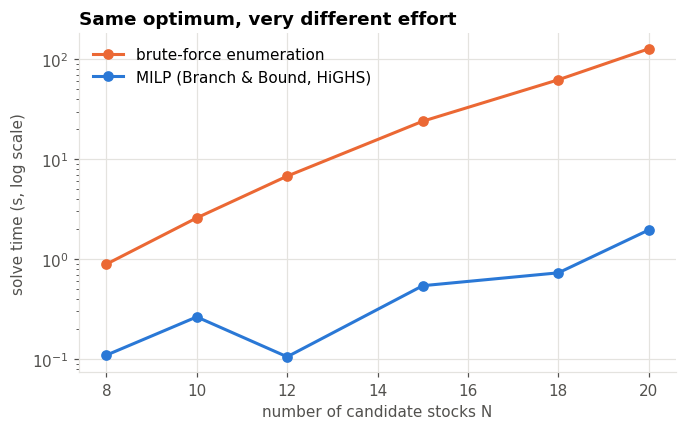

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
g = val.groupby("n")[["milp_time", "brute_force_time"]].mean()
ax.plot(g.index, g["brute_force_time"], "o-", color=ORANGE, label="brute-force enumeration")
ax.plot(g.index, g["milp_time"], "o-", color=BLUE, label="MILP (Branch & Bound, HiGHS)")
ax.set_yscale("log")
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("solve time (s, log scale)")
ax.set_title("Same optimum, very different effort")
ax.legend(loc="upper left")
save(fig, "02_validation_runtime")

**Result.** On all 18 instances the MILP finds the **same optimum and the same stocks** as brute force (differences ≤ 4 × 10⁻¹⁰, i.e. floating-point rounding). Brute-force time grows with the number of subsets (21,699 LPs and about 2 minutes at N = 20); Branch & Bound needs about 2 seconds, because it prunes most subsets without ever solving them.

### 9.2 The full problem: 457 stocks
We solve the real problem with a 30-minute limit, in both variants (continuous weights, and whole shares with ≤ 1% cash). We also record the LP relaxation (root) bound.

In [16]:
def run_main(variant):
    integer_shares = variant == "integer_shares"
    lp = solve(inst, relax=True, integer_shares=integer_shares)
    res = solve(inst, time_limit=MAIN_TIME_LIMIT, integer_shares=integer_shares)
    held = res["portfolio"]
    alloc = pd.DataFrame({"weight": held, "dollars": held * inst.budget, "price": inst.prices[held.index]})
    if integer_shares:
        alloc["shares"] = res["shares"][held.index]
        alloc["dollars"] = alloc["shares"] * alloc["price"]
    alloc.index.name = "ticker"
    alloc.to_csv(RESULTS_DIR / f"main_allocation_{variant}.csv")
    return result_row(res, inst, variant=variant) | {"lp_relaxation_bound": lp["mad"]}

main = run_experiment("main_summary", [{"variant": "continuous"}, {"variant": "integer_shares"}], run_main)
main = main.set_index("variant")
main[["status", "mad", "best_bound", "gap", "lp_relaxation_bound", "solve_time", "nodes",
      "n_variables", "n_constraints", "expected_annual_return", "annual_volatility", "n_held"]].T

variant,continuous,integer_shares
status,feasible (time limit),feasible (time limit)
mad,0.01007,0.01005
best_bound,0.00921,0.00928
gap,0.08581,0.07711
lp_relaxation_bound,0.00863,0.00858
solve_time,1800.21200,1800.37400
nodes,28016,61184
n_variables,1117,1574
n_constraints,1323,1781
expected_annual_return,0.20000,0.20019


In [17]:
alloc_c = pd.read_csv(RESULTS_DIR / "main_allocation_continuous.csv", index_col="ticker")
alloc_i = pd.read_csv(RESULTS_DIR / "main_allocation_integer_shares.csv", index_col="ticker")

print("Continuous weights")
display(alloc_c.style.format({"weight": "{:.1%}", "dollars": "${:,.2f}", "price": "${:,.2f}"}))

print(f"Whole-share purchase plan on 2016-12-30 (budget ${BUDGET:,.0f})")
plan = alloc_i.copy()
plan.loc["cash (unspent)"] = [1 - plan["weight"].sum(), BUDGET - plan["dollars"].sum(), np.nan, np.nan]
display(plan.style.format({"weight": "{:.2%}", "dollars": "${:,.2f}", "price": "${:,.2f}", "shares": "{:.0f}"},
                          na_rep=""))

# independent re-check with the evaluator
for name, alloc in [("continuous", alloc_c), ("integer_shares", alloc_i)]:
    ev = evaluate_weights(alloc["weight"].to_dict(), inst)
    assert ev["feasible"], ev["violations"]
    print(f"{name:15s} feasible={ev['feasible']}  MAD={ev['mad']:.5f}  E[return]={ev['expected_annual_return']:.1%}/yr  "
          f"volatility={ev['annual_volatility']:.1%}/yr  stocks={ev['n_assets']}")

Continuous weights


,weight,dollars,price
ticker,,,
CLX,27.7%,"$2,770.98",$120.02
RE,26.1%,"$2,611.86",$216.40
AZO,22.6%,"$2,256.58",$789.79
FB,13.3%,"$1,325.36",$115.05
HUM,10.4%,"$1,035.23",$204.03


Whole-share purchase plan on 2016-12-30 (budget $10,000)


,weight,dollars,price,shares
ticker,,,,
CLX,27.60%,"$2,760.46",$120.02,23
RE,23.80%,"$2,380.40",$216.40,11
AZO,23.69%,"$2,369.37",$789.79,3
FB,13.81%,"$1,380.60",$115.05,12
HUM,10.20%,"$1,020.15",$204.03,5
cash (unspent),0.89%,$89.02,,


continuous      feasible=True  MAD=0.01007  E[return]=20.0%/yr  volatility=9.9%/yr  stocks=5
integer_shares  feasible=True  MAD=0.01005  E[return]=20.0%/yr  volatility=9.9%/yr  stocks=5


**Result.**
* Both variants select **the same five stocks**: CLX (Clorox, consumer staples), RE (Everest Re, reinsurance), AZO (AutoZone, retail), FB (Facebook, technology) and HUM (Humana, health insurance). These five companies come from unrelated sectors, so their weekly deviations partly cancel.
* The 30-minute limit was reached. HiGHS found this portfolio early (within about 41 s in an exploratory run). The rest of the time raised the **lower bound** (root 0.00863 → 0.00921) without finding anything better. The remaining **certified gap of 8.6%** means *no* 5-stock portfolio can have more than 8.6% lower risk than this one.
* The whole-share plan spends **$9,910.98** and leaves $89.02 as cash. Its risk is marginally *lower* than the continuous one, because up to 1% may be held as risk-free cash. The two models have slightly different feasible sets, so this does not contradict optimality.
* **Modelling lesson:** the first version of the whole-share model had no cash limit. It returned a portfolio that kept **52% in cash**: cash has zero risk, so the model "parked" half the money and bought volatile high-return stocks to reach the target on paper. The 1% cap (`max_cash`) fixed this. An optimiser does exactly what the model says, not what we meant.

### 9.3 Scalability: how does Branch & Bound cope as N grows?
For each size $N$ we draw 3 random stock subsets (seeds 0–2), solve with a 300 s limit, and record time, nodes, final gap, and the **root gap** (how far the LP relaxation is from the best portfolio).

In [18]:
def run_scalability(n, seed):
    sub = random_subinstance(inst, n, seed) if n < inst.N else inst
    lp = solve(sub, relax=True)
    res = solve(sub, time_limit=TIME_LIMIT)
    return result_row(res, sub, n=n, seed=seed, time_limit=TIME_LIMIT) | {
        "lp_relaxation_bound": lp["mad"], "lp_time": round(lp["solve_time"], 3),
        "search_space_log10": math.log10(n_subsets(n))}

sizes = [10, 20, 30, 40, 50, 75, 100, 150, 200, 300, 457]
sc = run_experiment("scalability", [{"n": n, "seed": s} for n in sizes for s in ([0, 1, 2] if n < 457 else [0])],
                    run_scalability)
sc["root_gap"] = (sc["mad"] - sc["lp_relaxation_bound"]) / sc["mad"]
agg = sc.groupby("n").agg(runs=("seed", "count"), proven_optimal=("proven_optimal", "mean"),
                          mean_time_s=("solve_time", "mean"), max_time_s=("solve_time", "max"),
                          mean_nodes=("nodes", "mean"), mean_final_gap=("gap", "mean"),
                          mean_root_gap=("root_gap", "mean"), search_space_log10=("search_space_log10", "first"))
agg

,runs,proven_optimal,mean_time_s,max_time_s,mean_nodes,mean_final_gap,mean_root_gap,search_space_log10
n,,,,,,,,
10,3,1.00000,0.26500,0.30900,3.66667,0.00000,0.00770,2.80414
20,3,1.00000,1.15233,1.58300,18.33333,0.00000,0.02036,4.33644
30,3,1.00000,3.22433,4.34100,135.33333,0.00000,0.05598,5.24164
40,3,1.00000,10.36400,16.52500,360.66667,0.00000,0.05641,5.88087
50,3,1.00000,16.19133,27.80200,886.33333,0.00000,0.05702,6.37474
75,3,1.00000,66.74933,135.61100,2881.33333,0.00000,0.08192,7.26823
100,3,1.00000,73.62467,98.74500,2620.66667,0.00000,0.09143,7.89969
150,3,0.00000,300.19167,300.22600,10429.66667,0.04550,0.10276,8.78705
200,3,0.00000,300.13100,300.15500,7772.00000,0.07267,0.11730,9.41525


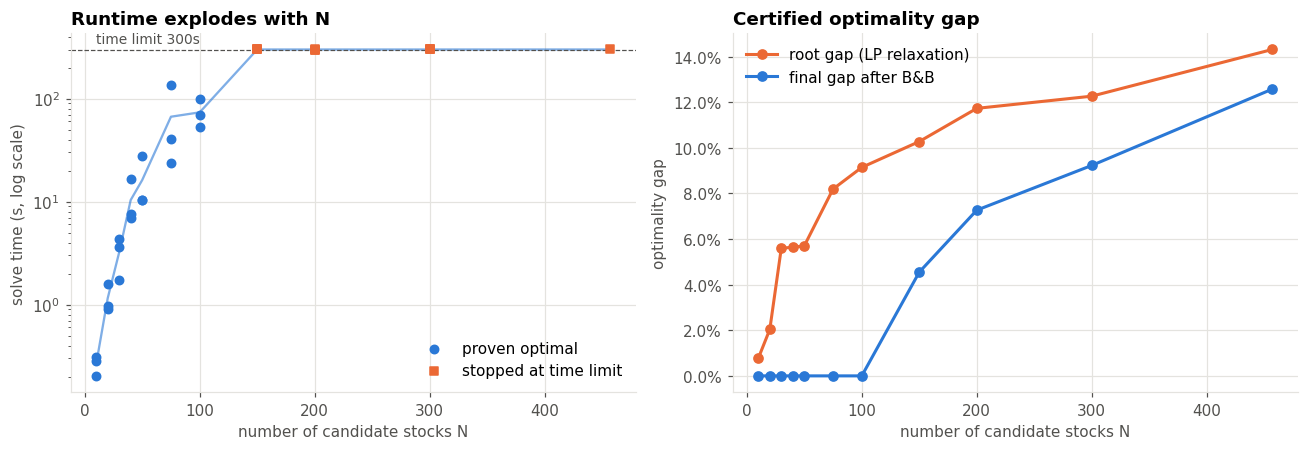

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
opt, lim = sc[sc["proven_optimal"]], sc[~sc["proven_optimal"]]
ax.scatter(opt["n"], opt["solve_time"], color=BLUE, s=30, label="proven optimal", zorder=3)
ax.scatter(lim["n"], lim["solve_time"], color=ORANGE, marker="s", s=30, label="stopped at time limit", zorder=3)
ax.plot(agg.index, agg["mean_time_s"], color=BLUE, lw=1.5, alpha=0.6)
ax.axhline(TIME_LIMIT, color=MUTED, lw=0.8, ls="--")
ax.text(10, TIME_LIMIT * 1.15, f"time limit {TIME_LIMIT}s", color=MUTED, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("solve time (s, log scale)")
ax.set_title("Runtime explodes with N")
ax.legend(loc="lower right")

ax = axes[1]
ax.plot(agg.index, agg["mean_root_gap"], "o-", color=ORANGE, label="root gap (LP relaxation)")
ax.plot(agg.index, agg["mean_final_gap"], "o-", color=BLUE, label="final gap after B&B")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("optimality gap")
ax.set_title("Certified optimality gap")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "02_scalability")

**Result.**
* **Up to N = 100** every instance is proven optimal (mean 74 s at N = 100). **From N = 150** no instance can be proven within 300 s. This is the practical face of NP-hardness: the number of subsets grows like $\binom{N}{5} \sim N^5$, and the B&B tree grows with it (from 4 nodes at N = 10 to ~10,000 at N = 150).
* The **root gap grows from 0.8% to 14.3%**, because the relaxation ignores the cardinality constraint (section 7). The larger the universe, the more the unrestricted portfolio can spread out, and the more work branching has to do.
* Even when stopped, the method returns a **certified** bound: on the full problem the answer is at most 12.6% (after 300 s) or 8.6% (after 30 min) from optimal.

### 9.4 Two independent solvers: HiGHS vs CBC

In [20]:
def run_solver(n, seed, solver):
    sub = random_subinstance(inst, n, seed)
    return result_row(solve(sub, solver=solver, time_limit=TIME_LIMIT), sub, n=n, seed=seed, time_limit=TIME_LIMIT)

sv = run_experiment("solver_comparison",
                    [{"n": n, "seed": s, "solver": slv} for n in [10, 20, 30, 40, 50] for s in [0, 1, 2]
                     for slv in ["highs", "cbc"]], run_solver)
g = sv.groupby(["n", "solver"])["solve_time"].mean().unstack()
g["CBC / HiGHS"] = g["cbc"] / g["highs"]
g

solver,cbc,highs,CBC / HiGHS
n,,,
10,0.76733,0.26100,2.93997
20,1.69667,1.17133,1.44849
30,5.79633,3.20633,1.80778
40,11.58067,9.47033,1.22284
50,22.66167,13.96200,1.62310


all runs proven optimal by both solvers: True


,solver,cbc,highs,relative_difference
n,seed,,,
20,0,0.01218,0.01218,0.00010
50,1,0.01216,0.01215,0.00077


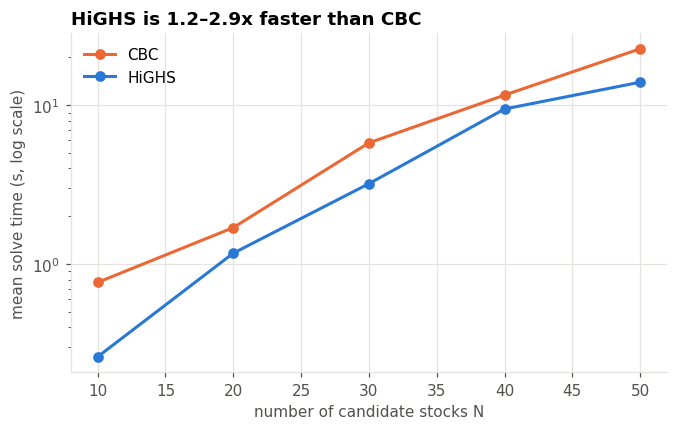

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(g.index, g["cbc"], "o-", color=ORANGE, label="CBC")
ax.plot(g.index, g["highs"], "o-", color=BLUE, label="HiGHS")
ax.set_yscale("log")
ax.set_xlabel("number of candidate stocks N")
ax.set_ylabel("mean solve time (s, log scale)")
ax.set_title("HiGHS is 1.2–2.9x faster than CBC")
ax.legend(loc="upper left")
save(fig, "02_solver_comparison")

both = sv.pivot_table(index=["n", "seed"], columns="solver", values="mad")
both["relative_difference"] = (both["cbc"] - both["highs"]) / both["highs"]
print("all runs proven optimal by both solvers:", sv["proven_optimal"].all())
both[both["relative_difference"].abs() > 1e-7]

**Finding: CBC's "optimal" is not always optimal.** Both solvers report *optimal* on all 15 instances and agree on 13. On 2 instances CBC returns a slightly worse portfolio (by 0.01% and 0.08%) while still claiming optimality. The next cell checks which solver is right, using tools that do not depend on either solver.

In [22]:
for n, seed in [(20, 0), (50, 1)]:
    sub = random_subinstance(inst, n, seed)
    for solver in ["highs", "cbc"]:
        r = solve(sub, solver=solver)
        idx = tuple(sub.tickers.index(t) for t in r["portfolio"].index)
        print(f"N={n} seed={seed} {solver:5s} claims {r['status']}: MAD {r['mad']:.7f} | "
              f"evaluator {evaluate_weights(r['weights'].values, sub)['mad']:.7f} | "
              f"fixed-subset LP {subset_lp(sub, idx):.7f} | {sorted(r['portfolio'].index)}")

N=20 seed=0 highs claims optimal: MAD 0.0121762 | evaluator 0.0121762 | fixed-subset LP 0.0121762 | ['EA', 'LMT', 'MLM', 'MRK', 'RSG']


N=20 seed=0 cbc   claims optimal: MAD 0.0121775 | evaluator 0.0121775 | fixed-subset LP 0.0121775 | ['EA', 'LMT', 'MRK', 'RSG', 'SLB']


N=50 seed=1 highs claims optimal: MAD 0.0121543 | evaluator 0.0121543 | fixed-subset LP 0.0121543 | ['ADBE', 'AZO', 'BDX', 'HBAN', 'WM']


N=50 seed=1 cbc   claims optimal: MAD 0.0121543 | evaluator 0.0121543 | fixed-subset LP 0.0121543 | ['ADBE', 'AZO', 'BDX', 'HBAN', 'WM']


* The HiGHS portfolios satisfy every constraint, and their risk is reproduced by the evaluator and by the fixed-subset LP. At N = 20 the HiGHS answer also matches brute force (section 9.1). So in the saved experiment **CBC pruned the true optimum** on both instances.
* On re-running, CBC **still misses the optimum at N = 20**, but at N = 50 it may now return the correct portfolio. CBC's answer on these instances depends on its settings: in our tests, the time-limit setting and switching presolve or cut generation on or off all changed whether the error appeared. This points to **floating-point tolerances** in CBC's search rather than an error in the model, which is identical for both solvers.

*Lesson:* an "exact" solver is only as exact as its numerical tolerances. Independent verification (brute force, a second solver, a separate evaluator) is part of using exact methods responsibly. HiGHS, which agreed with brute force everywhere, is our primary solver.

### 9.5 Efficient frontier: what does the 5-stock rule cost?
We vary the return target from 10% to 45% and solve:
* the **K = 5 MILP**;
* the **unconstrained** model (any number of stocks, no minimum weight). Here the binaries are redundant and the model is an ordinary LP.

In [23]:
unconstrained = replace(inst, K=inst.N, w_min=0.0)

def run_frontier(model, target):
    base = inst if model == "K=5 (MILP)" else unconstrained
    sub = replace(base, target=target / PERIODS_PER_YEAR)
    res = solve(sub, relax=model != "K=5 (MILP)", time_limit=TIME_LIMIT)
    return result_row(res, sub, model=model, target=target)

targets = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]
fr = run_experiment("frontier", [{"model": m, "target": t} for m in ["K=5 (MILP)", "unconstrained (LP)"]
                                 for t in targets], run_frontier)
fr[["model", "target", "status", "mad", "gap", "n_held", "solve_time"]]

,model,target,status,mad,gap,n_held,solve_time
0,K=5 (MILP),0.10000,feasible (time limit),0.00919,0.16650,5,300.19600
1,K=5 (MILP),0.15000,feasible (time limit),0.00932,0.13998,5,300.20100
2,K=5 (MILP),0.20000,feasible (time limit),0.01007,0.12575,5,300.18900
3,K=5 (MILP),0.25000,feasible (time limit),0.01124,0.11803,5,300.20000
4,K=5 (MILP),0.30000,feasible (time limit),0.01266,0.09553,5,300.21100
5,K=5 (MILP),0.35000,feasible (time limit),0.01420,0.05296,5,300.20700
6,K=5 (MILP),0.40000,optimal,0.01574,0.00000,5,103.21300
7,K=5 (MILP),0.45000,optimal,0.01766,0.00000,5,31.57300
8,unconstrained (LP),0.10000,optimal,0.00763,0.00000,33,0.42600
9,unconstrained (LP),0.15000,optimal,0.00792,0.00000,37,0.45500


model,K=5 (MILP),unconstrained (LP),extra risk (lower estimate),extra risk (upper estimate)
target,,,,
0.100000,0.00919,0.00763,0.3%,20.4%
0.150000,0.00932,0.00792,1.2%,17.6%
0.200000,0.01007,0.00863,2.0%,16.7%
0.250000,0.01124,0.00977,1.4%,15.0%
0.300000,0.01266,0.01118,2.5%,13.3%
0.350000,0.01420,0.01277,5.3%,11.2%
0.400000,0.01574,0.01447,8.8%,8.8%
0.450000,0.01766,0.01700,3.9%,3.9%


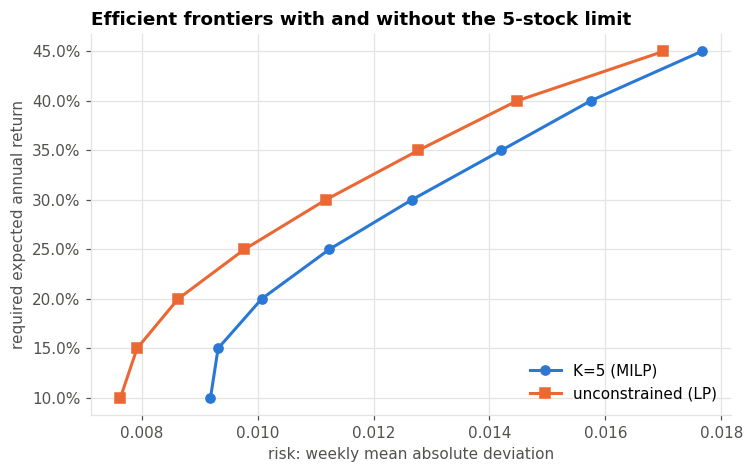

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for (name, grp), color, marker in zip(fr.groupby("model", sort=False), [BLUE, ORANGE], ["o", "s"]):
    ax.plot(grp["mad"], grp["target"], marker=marker, color=color, label=name)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("risk: weekly mean absolute deviation")
ax.set_ylabel("required expected annual return")
ax.set_title("Efficient frontiers with and without the 5-stock limit")
ax.legend(loc="lower right")
save(fig, "02_frontier")

wide = fr.pivot_table(index="target", columns="model", values="mad")
k5_bound = fr[fr["model"] == "K=5 (MILP)"].set_index("target")["best_bound"]
wide["extra risk (lower estimate)"] = k5_bound / wide["unconstrained (LP)"] - 1
wide["extra risk (upper estimate)"] = wide["K=5 (MILP)"] / wide["unconstrained (LP)"] - 1
wide.style.format({"K=5 (MILP)": "{:.5f}", "unconstrained (LP)": "{:.5f}",
                   "extra risk (lower estimate)": "{:.1%}", "extra risk (upper estimate)": "{:.1%}"})

**Result.**
* The unconstrained frontier (an LP, under 0.5 s per point) is the best risk achievable with **any** number of stocks; those portfolios hold 11–39 stocks. The gap between the curves is the **price of simplicity**: 4%–20% extra risk for an investor limited to five companies (about 17% at the 20% target). Most K = 5 points stopped at the time limit, so the true value lies between the lower and upper estimates.
* At the 20% target the unconstrained LP risk (0.00863) **equals the root bound of the 5-stock MILP** (section 9.2). This confirms numerically that the LP relaxation ignores the cardinality constraint.
* **Higher targets are easier to solve:** 40% and 45% are proven optimal in 103 s and 32 s. Only a few stocks have a high enough mean return, so the return constraint (4) prunes most of the tree.

### 9.6 Sensitivity to K (maximum number of stocks)

,K,status,mad,best_bound,gap,n_held,solve_time
0,3,feasible (time limit),0.01127,0.01051,0.06758,3,300.25500
1,4,feasible (time limit),0.01060,0.00910,0.14146,4,300.30700
2,5,feasible (time limit),0.01007,0.00880,0.12575,5,300.20100
3,6,feasible (time limit),0.00975,0.00879,0.09828,6,300.20200
4,8,feasible (time limit),0.00933,0.00878,0.05800,8,300.20800
5,10,feasible (time limit),0.00918,0.00874,0.04746,10,300.24800
6,15,feasible (time limit),0.00896,0.00884,0.01417,13,300.41200


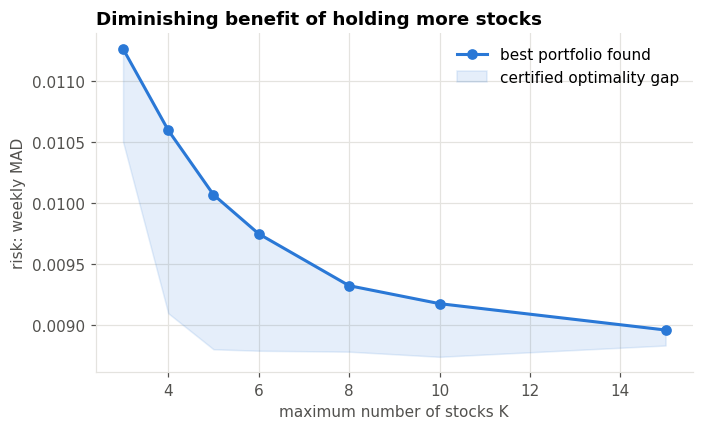

In [25]:
def run_cardinality(K):
    sub = replace(inst, K=K)
    return result_row(solve(sub, time_limit=TIME_LIMIT), sub, K=K)

ca = run_experiment("cardinality", [{"K": K} for K in [3, 4, 5, 6, 8, 10, 15]], run_cardinality)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ca["K"], ca["mad"], "o-", color=BLUE, label="best portfolio found")
ax.fill_between(ca["K"], ca["best_bound"], ca["mad"], color=BLUE, alpha=0.12, label="certified optimality gap")
ax.set_xlabel("maximum number of stocks K")
ax.set_ylabel("risk: weekly MAD")
ax.set_title("Diminishing benefit of holding more stocks")
ax.legend(loc="upper right")
save(fig, "02_cardinality")
ca[["K", "status", "mad", "best_bound", "gap", "n_held", "solve_time"]]

**Result.** Risk falls quickly from K = 3 to K = 6 and then flattens: going from 5 to 15 stocks reduces MAD by only about 11%. Allowing 5 stocks therefore captures most of the diversification benefit available within this limit. The shaded band is the certified gap: none of these runs was proven optimal within 300 s, but the true optimum must lie inside the band.